# Dobór progu klasyfikacji

In [26]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.compose import ColumnTransformer
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import (
    accuracy_score,
    average_precision_score,
    confusion_matrix,
    f1_score,
    fbeta_score,
    precision_score,
    recall_score,
    roc_auc_score,
)
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

RANDOM_STATE = 42
df = pd.read_csv("heart_disease_cleaned.csv")
df["target"] = (df["num"] > 0).astype(int)

thal_map = {"normal": 0, "reversable defect": 1, "fixed defect": 2}
df["chol_age"] = df["chol"] / df["age"]
df["thal_defect_severity"] = df["ca"] * df["thal"].map(thal_map)

X = df.drop(columns=["id", "dataset", "num", "target"])
y = df["target"]

## Podział danych

In [27]:
X_train, X_temp, y_train, y_temp = train_test_split(
    X, y, test_size=0.4, stratify=y, random_state=RANDOM_STATE
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=RANDOM_STATE
)

## Model i preprocessing

In [28]:
categorical_features = ["sex", "cp", "fbs", "restecg", "exang", "slope", "ca", "thal"]
numeric_features = [col for col in X_train.columns if col not in categorical_features]

preprocessor = ColumnTransformer(
    transformers=[
        ("numeric", StandardScaler(), numeric_features),
        ("categorical", OneHotEncoder(handle_unknown="ignore"), categorical_features),
    ]
)

model = Pipeline(
    steps=[
        ("preprocessing", preprocessor),
        (
            "classifier",
            GradientBoostingClassifier(
                n_estimators=100,
                learning_rate=0.1,
                max_depth=3,
                min_samples_leaf=1,
                random_state=RANDOM_STATE,
            ),
        ),
    ]
)
_ = model.fit(X_train, y_train)

## Dobór progu na walidacji

In [29]:
valid_probabilities = model.predict_proba(X_valid)[:, 1]
threshold_rows = []

for step in range(5, 96):
    threshold = step / 100
    predictions = (valid_probabilities >= threshold).astype(int)
    threshold_rows.append({
        "Threshold": threshold,
        "Precision": precision_score(y_valid, predictions, zero_division=0),
        "Recall": recall_score(y_valid, predictions),
        "F2": fbeta_score(y_valid, predictions, beta=2, zero_division=0),
    })

threshold_results = pd.DataFrame(threshold_rows)
MIN_PRECISION = 0.80
feasible_thresholds = threshold_results.loc[
    threshold_results["Precision"] >= MIN_PRECISION
]
best_row = feasible_thresholds.sort_values(
    ["Recall", "F2", "Threshold"],
    ascending=[False, False, True],
).iloc[0]
best_threshold = best_row["Threshold"]
threshold_selection = best_row.to_frame().T
threshold_selection.insert(0, "Minimalna Precision", MIN_PRECISION)
print(threshold_selection.round(3))

    Minimalna Precision  Threshold  Precision  Recall     F2
25                  0.8        0.3      0.825   0.931  0.907


In [30]:
precision_floor_rows = []
for precision_floor in [0.75, 0.80, 0.85]:
    feasible_thresholds = threshold_results.loc[
        threshold_results["Precision"] >= precision_floor
    ]
    if not feasible_thresholds.empty:
        selected_row = feasible_thresholds.sort_values(
            ["Recall", "F2", "Threshold"],
            ascending=[False, False, True],
        ).iloc[0]
        precision_floor_rows.append({
            "Minimalna Precision": precision_floor,
            "Próg": selected_row["Threshold"],
            "Precision walidacja": selected_row["Precision"],
            "Recall walidacja": selected_row["Recall"],
            "F2 walidacja": selected_row["F2"],
        })

print(pd.DataFrame(precision_floor_rows).round(3))

   Minimalna Precision  Próg  Precision walidacja  Recall walidacja  \
0                 0.75  0.26                0.792             0.941   
1                 0.80  0.30                0.825             0.931   
2                 0.85  0.54                0.880             0.871   

   F2 walidacja  
0         0.906  
1         0.907  
2         0.873  


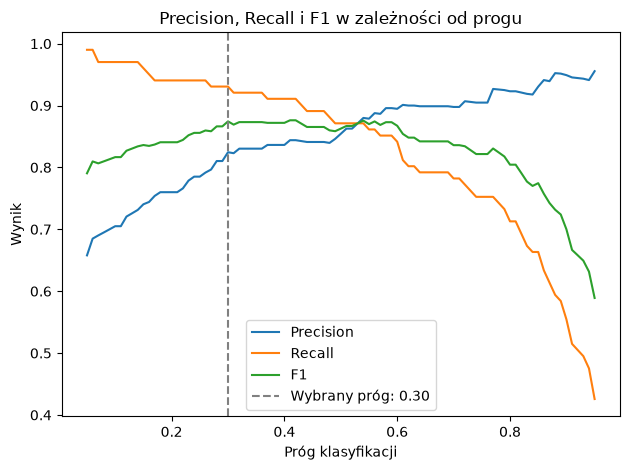

In [31]:
threshold_plot = threshold_results.copy()
threshold_plot["F1"] = [
    2 * precision * recall / (precision + recall) if precision + recall else 0
    for precision, recall in zip(threshold_plot["Precision"], threshold_plot["Recall"])
]

for metric in ["Precision", "Recall", "F1"]:
    plt.plot(threshold_plot["Threshold"], threshold_plot[metric], label=metric)
plt.axvline(best_threshold, linestyle="--", color="gray", label=f"Wybrany próg: {best_threshold:.2f}")
plt.xlabel("Próg klasyfikacji")
plt.ylabel("Wynik")
plt.title("Precision, Recall i F1 w zależności od progu")
plt.legend()
plt.tight_layout()
plt.show()

## Końcowa ocena na teście

   Próg  Accuracy  Precision  Recall     F1     F2  ROC-AUC  PR-AUC
0  0.50     0.875      0.891   0.882  0.887  0.884    0.952   0.962
1  0.30     0.886      0.872   0.931  0.900  0.919    0.952   0.962


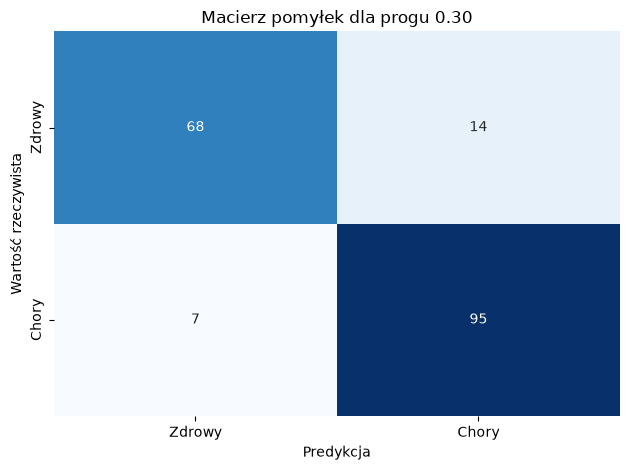

In [32]:
test_probabilities = model.predict_proba(X_test)[:, 1]
default_predictions = (test_probabilities >= 0.5).astype(int)
tuned_predictions = (test_probabilities >= best_threshold).astype(int)

comparison = pd.DataFrame([
    {
        "Próg": "0.50",
        "Accuracy": accuracy_score(y_test, default_predictions),
        "Precision": precision_score(y_test, default_predictions, zero_division=0),
        "Recall": recall_score(y_test, default_predictions),
        "F1": f1_score(y_test, default_predictions, zero_division=0),
        "F2": fbeta_score(y_test, default_predictions, beta=2, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, test_probabilities),
        "PR-AUC": average_precision_score(y_test, test_probabilities),
    },
    {
        "Próg": f"{best_threshold:.2f}",
        "Accuracy": accuracy_score(y_test, tuned_predictions),
        "Precision": precision_score(y_test, tuned_predictions, zero_division=0),
        "Recall": recall_score(y_test, tuned_predictions),
        "F1": f1_score(y_test, tuned_predictions, zero_division=0),
        "F2": fbeta_score(y_test, tuned_predictions, beta=2, zero_division=0),
        "ROC-AUC": roc_auc_score(y_test, test_probabilities),
        "PR-AUC": average_precision_score(y_test, test_probabilities),
    },
])
print(comparison.round(3))

default_recall = recall_score(y_test, default_predictions)
tuned_recall = recall_score(y_test, tuned_predictions)
tuned_precision = precision_score(y_test, tuned_predictions, zero_division=0)


sns.heatmap(
    confusion_matrix(y_test, tuned_predictions, labels=[0, 1]),
    annot=True,
    fmt="d",
    cmap="Blues",
    cbar=False,
    xticklabels=["Zdrowy", "Chory"],
    yticklabels=["Zdrowy", "Chory"],
)
plt.title(f"Macierz pomyłek dla progu {best_threshold:.2f}")
plt.xlabel("Predykcja")
plt.ylabel("Wartość rzeczywista")
plt.tight_layout()
plt.show()